# Lab 07: How to search documents by meaning

**CPU | API key: `OPENAI_API_KEY` (Part B runs without one) | Self-study**

A rep who asks *when does the link stop working?* has no file name to give, so the copilot must find the policy from
what the question means. In this self-study lab you build that search yourself. Lab 08 builds its own search and does
not need this lab.

## Goal

Search the support handbook by meaning, and know what a search score can and cannot tell you. The moment that teaches it: the
search returns three chunks with scores for every question, and the best score is not a reliable sign that the
handbook covers the question. *Do we take Bitcoin?*, which the payment policy answers, scores 0.3248, about the same
as *Do we match a lower price from another store?* (0.3253), which no policy covers. *Can a customer pay in monthly
instalments?*, also not covered, scores 0.4915, higher than five of the twelve covered questions.

## What you will learn

- How to compute cosine similarity by hand.
- How to split a handbook by size and by heading, and choose by where a rule lands and which file its chunk names.
- How to build, save, load and search an exact FAISS index of the handbook.
- How to predict the top file for a question, check it, and explain a miss from what each chunk holds.
- How to test, on labelled questions, whether a score can tell a covered question from an uncovered one.
- What FAISS leaves to you (the text, the metadata, a filter by rep), which a vector store takes over.

## Set up the notebook

Run these two cells first, every time; Lab 00 explains each line. **Setup** finds the repository folder (on Colab it
copies the repository and installs the packages first). **Config** reads `models.env` and finds your key. This lab uses
only `EMBED_MODEL`; it calls no chat model.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


The upper box of the picture runs once, whenever the handbook changes; the lower box runs for every question. The
last step returns three chunks whether or not any of them answers.

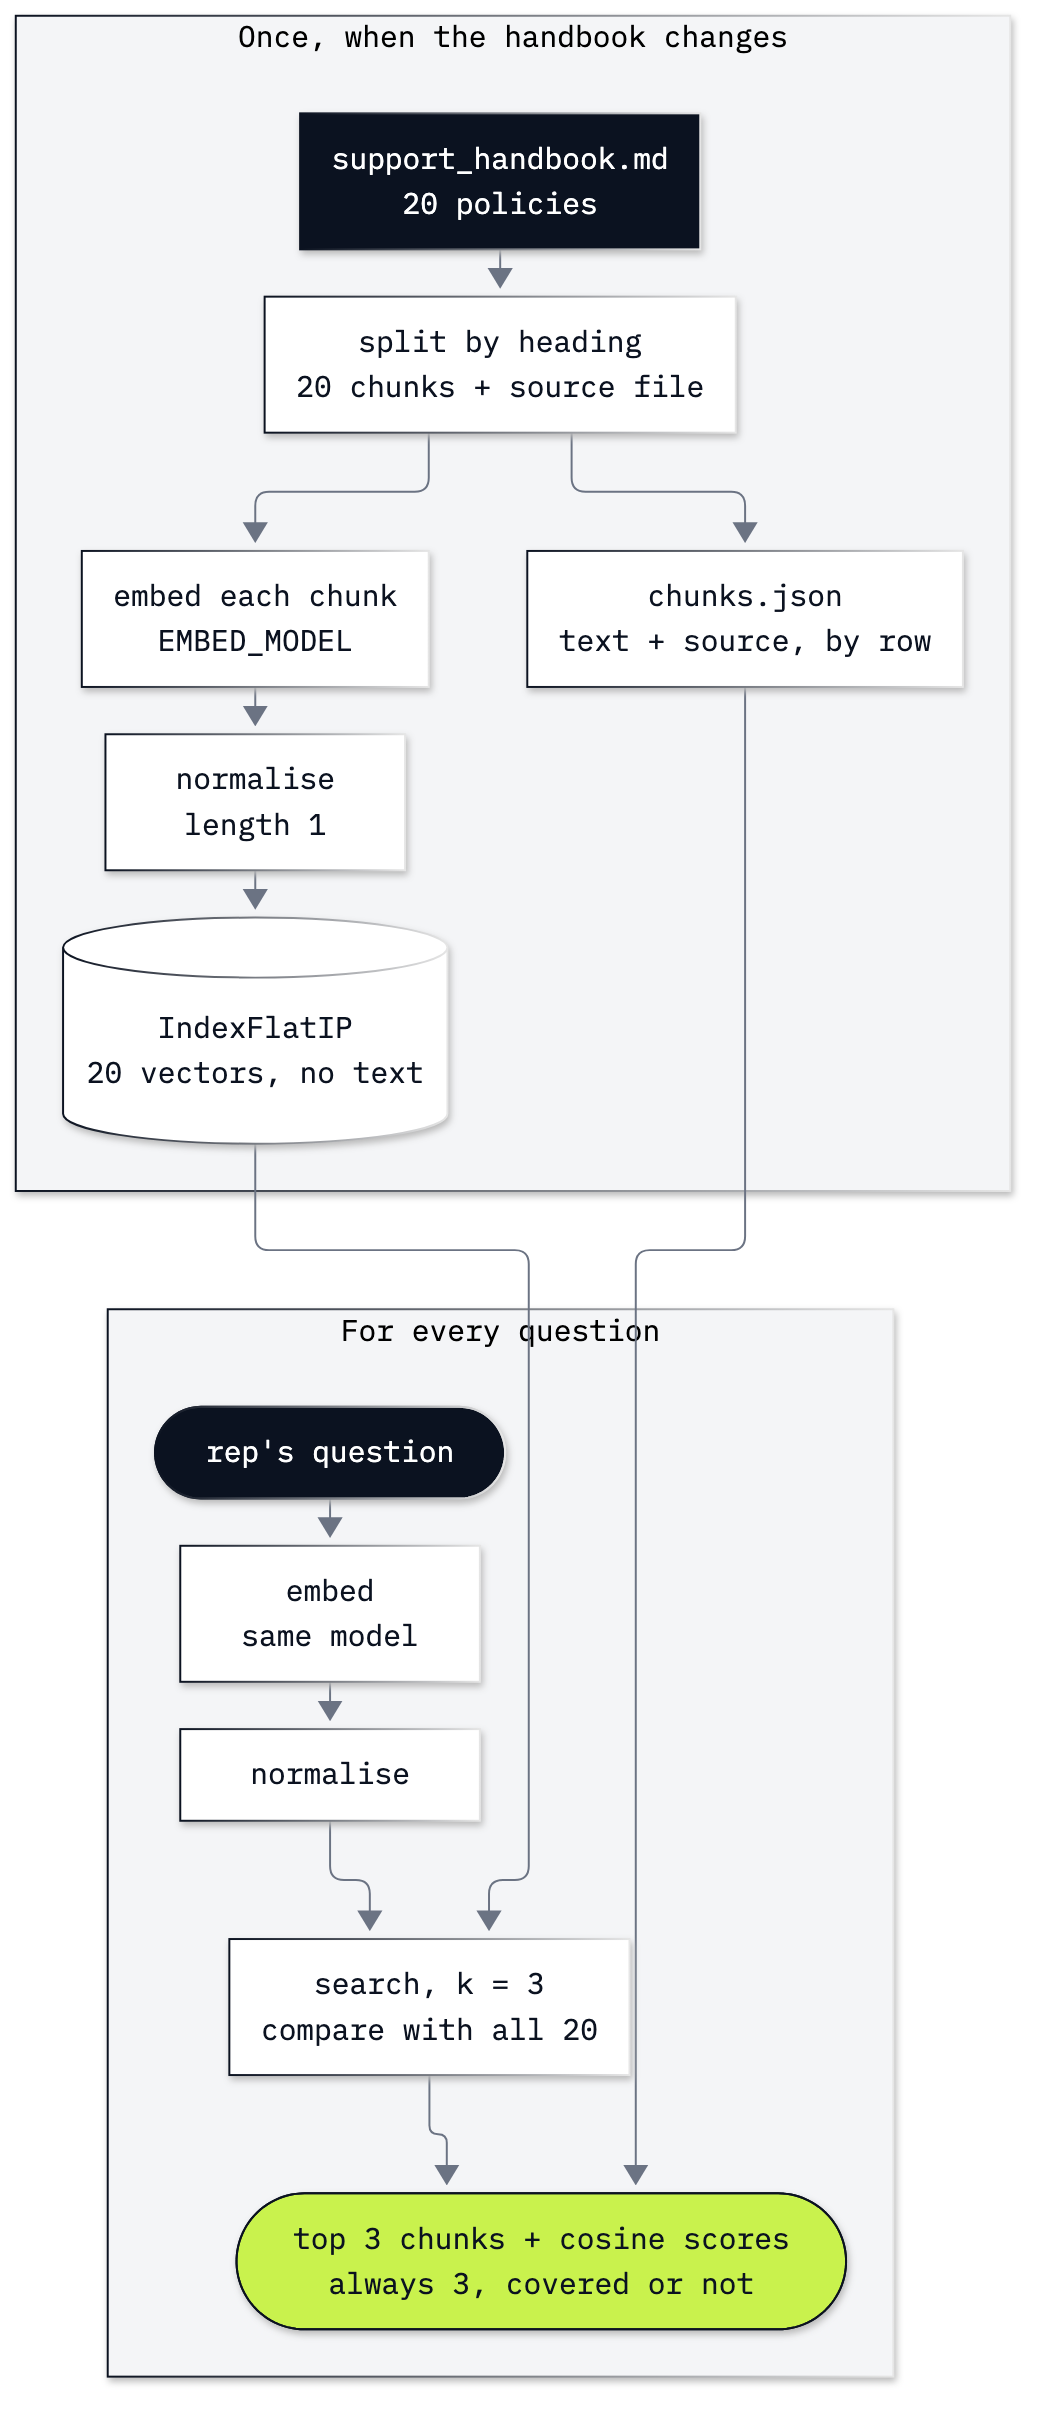

In [3]:
from IPython.display import Image

LAB = ROOT / "07_FAISS_Index_Handbook"
Image(filename=LAB / "resources" / "index_and_search.png", width=420)

---

## Part A: Measure closeness with cosine similarity

Part A gives you the measure the search ranks by: one number that says how close two texts are in meaning.

An **embedding** is a list of numbers, a **vector**, computed for a text so that similar meanings point in similar
directions. Multiply two vectors' matching numbers and add them up (the **dot product**), then divide by the two
lengths: that is **cosine similarity**, 1 for the same direction, 0 for unrelated. Start with a question `q` and two
documents `A` and `B`, two numbers each.

In [4]:
import numpy as np

q = np.array([1.0, 1.0])
A = np.array([1.0, 1.0])
B = np.array([5.0, 0.0])
print("dot(q, A) =", q @ A)
print("dot(q, B) =", q @ B)

dot(q, A) = 2.0
dot(q, B) = 5.0


`@` is the dot product. B has the bigger one, 5 against 2, only because B is long. Divide by both lengths and the
effect of length is gone.

In [5]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

print("lengths: q", round(float(np.linalg.norm(q)), 3), "A", round(float(np.linalg.norm(A)), 3), "B", float(np.linalg.norm(B)))
print("cosine(q, A) =", round(cosine(q, A), 4))
print("cosine(q, B) =", round(cosine(q, B), 4))

lengths: q 1.414 A 1.414 B 5.0
cosine(q, A) = 1.0
cosine(q, B) = 0.7071


A points exactly the way `q` points (1.0); B is 45 degrees away (0.7071). By cosine, A is closer: the opposite order.

Now real text, through OpenAI's embeddings endpoint and the model `models.env` names. Before you run the cell, write
down which two of the three rep questions you expect to be closest.

In [6]:
from openai import OpenAI

client = OpenAI()
SENTENCES = [
    "How long does a download link last?",
    "When does the link to download an album expire?",
    "Do we ship vinyl records to Chile?",
]
response = client.embeddings.create(model=settings["EMBED_MODEL"], input=SENTENCES)
vectors = np.array([item.embedding for item in response.data])
print("model:", response.model)
print("shape:", vectors.shape)
print("lengths:", np.round(np.linalg.norm(vectors, axis=1), 4))

model: text-embedding-3-small
shape: (3, 1536)
lengths: [1.     0.9999 1.0002]


One call returned one vector per sentence, 1,536 numbers each (fixed by the model). Every length is 1 to about three
decimals: OpenAI returns embeddings already **normalised** to length 1
([embeddings guide](https://developers.openai.com/api/docs/guides/embeddings)), so `cosine` divides by 1 and the dot
product alone is the cosine. The next cell prints both.

In [7]:
for i, j in [(0, 1), (0, 2), (1, 2)]:
    print(f"sentences {i + 1} and {j + 1}: cosine {cosine(vectors[i], vectors[j]):.4f}   dot {vectors[i] @ vectors[j]:.4f}")

sentences 1 and 2: cosine 0.7059   dot 0.7058
sentences 1 and 3: cosine 0.1140   dot 0.1140
sentences 2 and 3: cosine 0.2407   dot 0.2407


Sentences 1 and 2 score 0.7059, far above the pairs with the shipping question (0.1140 and 0.2407): they share few
words but ask the same thing. The dot product agrees with the cosine. A score of 0.7 does not mean "70 percent the
same"; another embedding model gives other values for the same pair.

### Checkpoint A

| You should see | Our run |
|---|---|
| Real vectors | `(3, 1536)`, lengths 1.0 to about three decimals |
| Cosines | 1–2 0.7059, 1–3 0.1140, 2–3 0.2407 (the fourth decimal can move) |

---

## Part B: Split the handbook two ways

Part B decides what one stored vector stands for. The search can only return what you stored, so the way you cut the
handbook decides whether a rule is found whole, with the file a citation needs.

A **chunk** is one piece of a document, embedded and returned as a unit. Too big, and one vector mixes topics; too
small, and a rule loses its context. The handbook joins the shop's 20 policies into one document.

In [8]:
HANDBOOK = ROOT / "data" / "handbook" / "support_handbook.md"
text = HANDBOOK.read_text(encoding="utf-8")
print(len(text), "characters,", text.count("\n## "), "policy headings")
start = text.index("## Refunds")
print(text[start:text.index("## Returns")])

7428 characters, 20 policy headings
## Refunds
Source: policy_refunds.md

Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.

Partial refunds are allowed when only some tracks on a multi-disc set are defective.

We do not refund because a customer changed their mind about a digital purchase.

Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.




Every policy has a `##` heading and a `Source:` line with its file name. This part follows the refunds policy's last
line, the duplicate-charge rule.

**Split A, by size.** `RecursiveCharacterTextSplitter`, where LangChain's
[text splitters](https://docs.langchain.com/oss/python/integrations/splitters) page tells you to start, cuts at blank
lines, then line breaks, then spaces, until every piece fits `chunk_size` characters. **Overlap** repeats the end of
one chunk at the start of the next. Use 1,000 characters with 200 of overlap, common tutorial settings.

In [9]:
import statistics
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter_a = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
split_a = splitter_a.split_text(text)
sizes_a = [len(chunk) for chunk in split_a]
print(len(split_a), "chunks; characters min", min(sizes_a), "median", statistics.median(sizes_a), "max", max(sizes_a))
print("characters repeated through overlap:", sum(sizes_a) - len(text))

10 chunks; characters min 289 median 945.5 max 991
characters repeated through overlap: 1443


Ten chunks, and 1,443 characters stored twice. Now find the rule: for every chunk, whether it holds the whole rule,
its headings and its `Source:` lines.

In [10]:
import re

RULE = "Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full."

def describe(chunk_texts):
    for number, chunk in enumerate(chunk_texts):
        headings = re.findall(r"^## (.+)$", chunk, flags=re.MULTILINE)
        sources = re.findall(r"Source: (\S+)", chunk)
        print(f"chunk {number}: {len(chunk):4} chars | rule whole: {RULE in chunk!s:5} | headings {headings} | sources {sources}")

describe(split_a)

chunk 0:  955 chars | rule whole: False | headings ['Accounts', 'Cancellations', 'Damaged media'] | sources ['policy_accounts.md', 'policy_cancellations.md', 'policy_damaged_media.md']
chunk 1:  903 chars | rule whole: False | headings ['Damaged media', 'Data retention', 'Digital downloads'] | sources ['policy_damaged_media.md', 'policy_data_retention.md', 'policy_digital_downloads.md']
chunk 2:  988 chars | rule whole: False | headings ['Escalations', 'Exchanges'] | sources ['policy_escalations.md', 'policy_exchanges.md']
chunk 3:  988 chars | rule whole: False | headings ['Gift cards', 'International orders'] | sources ['policy_gift_cards.md', 'policy_international.md']
chunk 4:  923 chars | rule whole: False | headings ['Library and playlists', 'Payment', 'Preorders'] | sources ['policy_library.md', 'policy_payment.md', 'policy_preorders.md']
chunk 5:  991 chars | rule whole: False | headings ['Preorders', 'Privacy', 'Refunds'] | sources ['policy_preorders.md', 'policy_privacy.md', 

Chunk 6 (Python counts from 0) holds the whole rule, but its headings are Returns and Shipping and its `Source:`
lines name `policy_returns.md` and `policy_shipping.md`; the refunds heading landed in chunk 5. A copilot that cites a
chunk's `Source:` line would cite the returns policy for a refunds rule.

**Split B, by heading.** `MarkdownHeaderTextSplitter` starts a chunk at each heading you name and records the heading as
metadata ([split markdown](https://docs.langchain.com/oss/python/integrations/splitters/markdown_header_metadata_splitter)).
`strip_headers=False` keeps the heading in the chunk's text, so the embedding sees it too.

In [11]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

splitter_b = MarkdownHeaderTextSplitter(headers_to_split_on=[("##", "policy")], strip_headers=False)
docs_b = splitter_b.split_text(text)
print(len(docs_b), "pieces")
print("piece 0 metadata:", docs_b[0].metadata)
print("piece 1 metadata:", docs_b[1].metadata)

21 pieces
piece 0 metadata: {}
piece 1 metadata: {'policy': 'Accounts'}


21 pieces: the title paragraph (no `policy` metadata) and one per policy. Keep the 20 policies, each as a dictionary
with its text, its policy name and the file from its `Source:` line, which a citation will name.

In [12]:
chunks = []
for doc in docs_b:
    if "policy" in doc.metadata:                      # skip the title paragraph
        source = doc.page_content.split("Source: ")[1].split()[0]
        chunks.append({"text": doc.page_content, "source": source, "policy": doc.metadata["policy"]})

sizes_b = [len(chunk["text"]) for chunk in chunks]
print(len(chunks), "chunks; characters min", min(sizes_b), "median", statistics.median(sizes_b), "max", max(sizes_b))
describe([chunk["text"] for chunk in chunks])

20 chunks; characters min 277 median 345.0 max 493
chunk 0:  400 chars | rule whole: False | headings ['Accounts'] | sources ['policy_accounts.md']
chunk 1:  340 chars | rule whole: False | headings ['Cancellations'] | sources ['policy_cancellations.md']
chunk 2:  315 chars | rule whole: False | headings ['Damaged media'] | sources ['policy_damaged_media.md']
chunk 3:  301 chars | rule whole: False | headings ['Data retention'] | sources ['policy_data_retention.md']
chunk 4:  437 chars | rule whole: False | headings ['Digital downloads'] | sources ['policy_digital_downloads.md']
chunk 5:  376 chars | rule whole: False | headings ['Escalations'] | sources ['policy_escalations.md']
chunk 6:  340 chars | rule whole: False | headings ['Exchanges'] | sources ['policy_exchanges.md']
chunk 7:  283 chars | rule whole: False | headings ['Gift cards'] | sources ['policy_gift_cards.md']
chunk 8:  412 chars | rule whole: False | headings ['International orders'] | sources ['policy_international.md

| Split | Chunks | Characters: min, median, max | Rule whole in | Names its own file? |
|---|---|---|---|---|
| A, by size | 10 | 289, 945.5, 991 | chunk 6, with Returns and Shipping | no: `policy_returns.md`, `policy_shipping.md` |
| B, by heading | 20 | 277, 345, 493 | chunk 13, refunds only | yes: `policy_refunds.md` |

Split B fits this handbook because each policy is short and has a heading; a long policy would need a split by size
inside each section too (Challenge 2). The rest of the lab uses split B's 20 chunks.

### Checkpoint B

The handbook has 7,428 characters and 20 policy headings, and your splits match the table above exactly: no model was
called in this part.

---

## Part C: Build an exact index with FAISS

Part C builds the structure that holds the vectors and returns the nearest ones: first on the toy vectors, where you
can check every number, then on the 20 chunks.

A **vector index** stores vectors and returns the ones nearest to a query vector.
[FAISS](https://github.com/facebookresearch/faiss) (`faiss-cpu` 1.15.1) does this in memory. `IndexFlatIP` compares
the query with every stored vector by **inner product** (the dot product), so it is **exact**: no vector is skipped.

FAISS is the fundamental here: it does only the core job of every vector store, so you see that job whole. In
practice LangChain's documentation uses `InMemoryVectorStore` (in `langchain-core`), which keeps each vector with its
text and metadata, and a vector database such as Qdrant or pgvector when the data grows
([vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores)); Lab 08 uses `InMemoryVectorStore`.
Older tutorials import `FAISS` from `langchain_community`, archived on 19 June 2026; this lab calls `faiss-cpu` itself.

Add the toy documents A and B as they are, and search with `q`.

In [13]:
import faiss

docs = np.array([[1, 1], [5, 0]], dtype="float32")   # A, B
query = np.array([[1, 1]], dtype="float32")          # q

raw = faiss.IndexFlatIP(2)                           # 2 numbers per vector
raw.add(docs)
scores, ids = raw.search(query, 2)
print("scores:", scores)
print("row numbers:", ids)

scores: [[5. 2.]]
row numbers: [[1 0]]


`search` returns the scores, best first, and the **row numbers** of the matching vectors, in the order they were
added. FAISS keeps no names and no text; the row number is how you find your own data again. Row 1 is B: on raw
vectors the long vector wins. To rank by cosine, give every vector length 1 first, documents and query alike, with
`faiss.normalize_L2` (it works in place).

In [14]:
faiss.normalize_L2(docs)
faiss.normalize_L2(query)

toy_index = faiss.IndexFlatIP(2)
toy_index.add(docs)
scores, ids = toy_index.search(query, 2)
print("after normalize_L2:", [("AB"[i], round(float(s), 4)) for s, i in zip(scores[0], ids[0])])

after normalize_L2: [('A', 1.0), ('B', 0.7071)]


After normalising, the inner product is the cosine (A 1.0, B 0.7071), so `IndexFlatIP` is a cosine search. OpenAI's
vectors already have length 1; keep the step anyway, so the code still ranks by cosine if `EMBED_MODEL` changes.

Now the handbook, with the toy's steps: embed, normalise, add. From here on the lab embeds through LangChain's
`OpenAIEmbeddings` (the same endpoint; Lab 08's vector store takes it), always with the model named. FAISS works in
`float32`.

In [15]:
from langchain_openai import OpenAIEmbeddings

emb = OpenAIEmbeddings(model=settings["EMBED_MODEL"])
texts = [chunk["text"] for chunk in chunks]
chunk_vectors = np.array(emb.embed_documents(texts), dtype="float32")
faiss.normalize_L2(chunk_vectors)

handbook_index = faiss.IndexFlatIP(chunk_vectors.shape[1])
handbook_index.add(chunk_vectors)
print("shape:", chunk_vectors.shape, "| ntotal", handbook_index.ntotal, "| d", handbook_index.d)

shape: (20, 1536) | ntotal 20 | d 1536


`ntotal` is the number of vectors and `d` the numbers in each. Rows follow the order of `chunks`, so row 13 is the
refunds chunk. Now the search: embed the question with **the same model** as the chunks (vectors from two models cannot
be compared), normalise it, ask for the `k` nearest, and turn row numbers back into chunks.

In [16]:
def search(query, k=3, index=handbook_index, chunks=chunks):
    """The k chunks closest to a query, best first, as (cosine score, chunk) pairs."""
    vector = np.array([emb.embed_query(query)], dtype="float32")
    faiss.normalize_L2(vector)                       # like the chunks
    scores, ids = index.search(vector, k)
    return [(float(score), chunks[i]) for score, i in zip(scores[0], ids[0])]

question = "She bought the same album twice by mistake. Can she get her money back?"
for score, chunk in search(question):
    print(f"{score:.4f}  {chunk['source']}")

0.4423  policy_refunds.md
0.3792  policy_damaged_media.md
0.3496  policy_digital_downloads.md


The question says *bought twice* and *money back*; the rule says *duplicate charges* and *refund*. The refunds chunk
still comes first, at 0.4423: search by meaning.

### Checkpoint C

| You should see | Our run |
|---|---|
| Toy index | raw: rows `[[1 0]]`; normalised: A 1.0, B 0.7071 |
| Handbook index | `(20, 1536)`, `ntotal 20`, `d 1536` |
| Bought-twice question | `policy_refunds.md` 0.4423, `policy_damaged_media.md` 0.3792, `policy_digital_downloads.md` 0.3496; the fourth decimal can move |

---

## Part D: Save the index and load it back

Part D keeps the index between sessions, so the handbook is embedded once and not every time the notebook starts.

`faiss.write_index` saves an index and `faiss.read_index` loads it. The file holds only vectors, so save the chunks
beside it as JSON: without them a row number points to nothing. Both go in `my_index/` in this lab's folder (git
ignores it).

In [17]:
import json

MY_INDEX = LAB / "my_index"
MY_INDEX.mkdir(exist_ok=True)
faiss.write_index(handbook_index, str(MY_INDEX / "handbook.faiss"))
(MY_INDEX / "chunks.json").write_text(json.dumps(chunks, indent=1), encoding="utf-8")
for file in sorted(MY_INDEX.iterdir()):
    print(f"{file.name:15} {file.stat().st_size:7} bytes")

chunks.json        9097 bytes
handbook.faiss   122925 bytes


The index file is 20 vectors × 1,536 numbers × 4 bytes plus a short header. Load both back and search with them.

In [18]:
loaded_index = faiss.read_index(str(MY_INDEX / "handbook.faiss"))
loaded_chunks = json.loads((MY_INDEX / "chunks.json").read_text(encoding="utf-8"))
print(type(loaded_index).__name__, "ntotal", loaded_index.ntotal, "d", loaded_index.d)
print("same vectors as before:", bool((loaded_index.reconstruct_n(0, 20) == handbook_index.reconstruct_n(0, 20)).all()))
for score, chunk in search(question, index=loaded_index, chunks=loaded_chunks):
    print(f"{score:.4f}  {chunk['source']}")

IndexFlatIP ntotal 20 d 1536
same vectors as before: True


0.4423  policy_refunds.md
0.3792  policy_damaged_media.md
0.3496  policy_digital_downloads.md


`reconstruct_n` reads stored vectors back: the loaded ones are exactly those you saved, and the search returns the
same files.

⚠️ The [FAISS wiki](https://github.com/facebookresearch/faiss/wiki/Index-IO,-cloning-and-hyper-parameter-tuning) warns
that a crafted index file can run code when read. Load only index files you wrote or trust.

### Checkpoint D

| You should see | Our run |
|---|---|
| Saved files | `chunks.json` (9,097 bytes) and `handbook.faiss` (122,925 bytes) |
| Loaded index | `IndexFlatIP ntotal 20 d 1536`, same vectors `True`, Part C's three files in order |

---

## Part E: Predict the top file, then search

Part E tests the search the way you will use it: on rep questions whose answer you can find yourself.

Read the four questions, find the policy that answers each, and predict which file the search ranks first. Watch for
shared words: *warped* appears in two policies.

In [19]:
QUESTIONS = {
    1: "When does a customer's download link stop working?",
    2: "The vinyl arrived warped. What do we offer?",
    3: "Can a student get money off a digital album?",
    4: "The parcel has shipped. Can we redirect it to her holiday address?",
}
ANSWERS = {          # the file whose text answers the question
    1: "policy_digital_downloads.md",
    2: "policy_damaged_media.md",
    3: "policy_student_discount.md",
    4: "policy_international.md",
}
my_prediction = dict(ANSWERS)    # change any file you expect the search to rank first instead

`ANSWERS` comes from reading the policies: *We do not redirect a parcel in transit* is in the international orders
policy. Change `my_prediction` to your own guess, then search.

In [20]:
for number, q in QUESTIONS.items():
    hits = search(q)
    files = [c["source"] for s, c in hits]
    rank = files.index(ANSWERS[number]) + 1 if ANSWERS[number] in files else "not in top 3"
    print(f"Q{number}: {q}")
    print("    " + "   ".join(f"{c['source']} {s:.4f}" for s, c in hits))
    print(f"    answering file at rank {rank}; prediction right: {files[0] == my_prediction[number]}")

Q1: When does a customer's download link stop working?
    policy_digital_downloads.md 0.6055   policy_cancellations.md 0.3330   policy_library.md 0.3240
    answering file at rank 1; prediction right: True
Q2: The vinyl arrived warped. What do we offer?
    policy_damaged_media.md 0.5550   policy_warranty.md 0.3895   policy_returns.md 0.3363
    answering file at rank 1; prediction right: True


Q3: Can a student get money off a digital album?
    policy_student_discount.md 0.5731   policy_digital_downloads.md 0.5070   policy_refunds.md 0.4405
    answering file at rank 1; prediction right: True


Q4: The parcel has shipped. Can we redirect it to her holiday address?
    policy_shipping.md 0.3875   policy_international.md 0.3680   policy_cancellations.md 0.2985
    answering file at rank 2; prediction right: False


Questions 1 to 3 rank the answering file first. Question 4 does not: `policy_shipping.md` (0.3875) comes above `policy_international.md` (0.3680). A copilot that read only the top chunk would answer from the wrong policy. Compare the two chunks and the
question's words in each.

In [21]:
STOP = {"the", "has", "can", "we", "it", "to", "her", "a", "what", "do"}
question_words = set(re.findall(r"[a-z]+", QUESTIONS[4].lower())) - STOP
by_file = {c["source"]: c["text"] for c in chunks}
for file in ("policy_shipping.md", "policy_international.md"):
    found = sorted(w for w in question_words if w in by_file[file].lower())
    print(file, "contains:", found)
    print(by_file[file], "\n")

policy_shipping.md contains: ['address', 'parcel']
## Shipping
Source: policy_shipping.md  
Domestic (same country as the billing address): 3 to 7 business days.  
International: 10 to 21 business days. Customs fees are the customer's.  
We ship physical orders once. We do not split a single invoice across two parcels.  
Free shipping on physical orders over 50 dollars before tax. 

policy_international.md contains: ['parcel', 'redirect', 'shipped']
## International orders
Source: policy_international.md  
We ship physical goods to the country on the invoice. We do not redirect a parcel in transit.  
VAT or sales tax is calculated at checkout for the billing country. We do not add a second tax after the invoice is issued.  
Some titles are licensed for one region only. Those cannot be shipped outside that region. The product page says so before purchase. 



The international chunk shares more of the question's words and still ranks second. A chunk's vector stands for the
whole chunk, and this one is about three things: where we ship, sales tax, region-locked titles. The shipping chunk is
all about parcels and delivery, the question's topic, though it never says whether a parcel can be redirected. The
search finds the closest topic, not the answer.

Question 2 is a trap for the reader instead: the warranty policy says *warped* too, about a sleeve left in the sun. The
search ranked it second (0.3895).

### Checkpoint E

| You should see | Our run |
|---|---|
| Questions 1 to 3 | the answering file first: 0.6055, 0.5550 and 0.5731 |
| Question 4 | `policy_shipping.md` 0.3875 first, `policy_international.md` second |

Scores can move in the fourth decimal; check the order.

---

## Part F: Test whether a score shows the handbook covers a question

Part F asks what the scores can tell you. A copilot should say *the handbook does not cover this* when no policy
answers; here you find out whether the search score can make that call.

No policy says anything about matching a competitor's price. Search for it.

In [22]:
uncovered = "Do we match a lower price from another store?"
for score, chunk in search(uncovered):
    print(f"{score:.4f}  {chunk['source']}")

0.3253  policy_exchanges.md
0.3118  policy_student_discount.md
0.2955  policy_payment.md


Three chunks, as for every question, and none mentions price matching. The top score, 0.3253, is below every top
score in Part E, which suggests a rule: below some threshold, say "not covered". Test it on 18 questions labelled before
any search: 12 that a policy answers (with its file) and 6 that none does (`None`), from close to the shop's business
to far from it.

In [23]:
LABELLED = [
    ("When does a customer's download link stop working?", "policy_digital_downloads.md"),
    ("The vinyl arrived warped. What do we offer?", "policy_damaged_media.md"),
    ("Can a student get money off a digital album?", "policy_student_discount.md"),
    ("The parcel has shipped. Can we redirect it to her holiday address?", "policy_international.md"),
    ("She bought the same album twice by mistake. Can she get her money back?", "policy_refunds.md"),
    ("Can a customer change the email on her account?", "policy_accounts.md"),
    ("Do we take Bitcoin?", "policy_payment.md"),
    ("The customer lost her gift card code. Can we send a new one?", "policy_gift_cards.md"),
    ("A song he bought is not showing in his library yet.", "policy_library.md"),
    ("Is support open on Saturday?", "policy_support_hours.md"),
    ("The preorder is two months late. Can she cancel?", "policy_preorders.md"),
    ("The record player needle he bought broke after six weeks. Is it covered?", "policy_warranty.md"),
    ("Do we match a lower price from another store?", None),
    ("Can a customer pay in monthly instalments?", None),
    ("Do we sell concert tickets?", None),
    ("Is there a loyalty points programme?", None),
    ("Can a rep work from home on Fridays?", None),
    ("What will the weather be in Lisbon tomorrow?", None),
]

Search each question once, keep its top score, and print the list from the highest score to the lowest.

In [24]:
results = []
for q, answer in LABELLED:
    top_score, top_chunk = search(q, k=1)[0]
    results.append({"question": q, "answer": answer, "top": top_chunk["source"], "score": top_score})

for r in sorted(results, key=lambda r: -r["score"]):
    label = "covered    " if r["answer"] else "NOT covered"
    note = "" if not r["answer"] else ("  top file answers" if r["top"] == r["answer"] else "  top file does not answer")
    print(f"{r['score']:.4f}  {label}  {r['top']:30}{note}  | {r['question']}")

0.6055  covered      policy_digital_downloads.md     top file answers  | When does a customer's download link stop working?
0.6009  covered      policy_preorders.md             top file answers  | The preorder is two months late. Can she cancel?
0.5731  covered      policy_student_discount.md      top file answers  | Can a student get money off a digital album?
0.5550  covered      policy_damaged_media.md         top file answers  | The vinyl arrived warped. What do we offer?
0.5114  covered      policy_gift_cards.md            top file answers  | The customer lost her gift card code. Can we send a new one?
0.5088  covered      policy_warranty.md              top file answers  | The record player needle he bought broke after six weeks. Is it covered?
0.5024  covered      policy_support_hours.md         top file answers  | Is support open on Saturday?
0.4915  NOT covered  policy_payment.md               | Can a customer pay in monthly instalments?
0.4849  covered      policy_library.md 

Read from the bottom up. *Do we take Bitcoin?* scores 0.3248, the lowest covered question, although the payment policy
answers it (*... or cryptocurrency*) and ranks first: the question says *Bitcoin*, and the policy's other lines are
about gift cards and split payments. Price matching, which nothing covers, scores about the same (0.3253). Higher
up, *monthly instalments* (0.4915) sits above five covered questions: close to the payment policy in topic,
which never mentions instalments.

Count what a few thresholds would do.

In [25]:
covered_scores = [r["score"] for r in results if r["answer"]]
uncovered_scores = [r["score"] for r in results if not r["answer"]]
print(f"lowest covered {min(covered_scores):.4f} | highest not covered {max(uncovered_scores):.4f}")
for threshold in (0.30, 0.33, 0.35, 0.40):
    refused = sum(s < threshold for s in covered_scores)
    let_through = sum(s >= threshold for s in uncovered_scores)
    print(f"threshold {threshold:.2f}: covered questions refused {refused} of {len(covered_scores)}, "
          f"uncovered questions answered {let_through} of {len(uncovered_scores)}")

lowest covered 0.3248 | highest not covered 0.4915
threshold 0.30: covered questions refused 0 of 12, uncovered questions answered 3 of 6
threshold 0.33: covered questions refused 1 of 12, uncovered questions answered 2 of 6
threshold 0.35: covered questions refused 1 of 12, uncovered questions answered 1 of 6
threshold 0.40: covered questions refused 2 of 12, uncovered questions answered 1 of 6


A threshold of 0.30 refuses no covered question but answers 3 of the 6 uncovered ones; 0.35 answers one uncovered question (instalments) and refuses Bitcoin; 0.40 refuses two covered questions and still answers instalments.

No threshold keeps every covered question and refuses every uncovered one: the highest uncovered score is above the
lowest covered score. A cosine score measures closeness in topic and wording, for this model, not the probability that
a chunk answers.

So who decides? The passages go to the chat model with an instruction to answer only from them and to say when they
do not answer, and code checks the reply: Lab 08. Hosted search offers a `score_threshold`
([OpenAI retrieval guide](https://developers.openai.com/api/docs/guides/retrieval)); choose it on labelled questions and
test it on others (Challenge 3).

### Checkpoint F

| You should see | Our run |
|---|---|
| Price match | `policy_exchanges.md` 0.3253, `policy_student_discount.md` 0.3118, `policy_payment.md` 0.2955; none answers |
| Labelled set | top file right for 11 of 12 covered questions; lowest covered 0.3248, highest not covered 0.4915 |

---

## Part G: Keep the text and metadata, and filter by rep

Part G does the jobs FAISS left to you, which a vector store takes over in Lab 08. Ask the index for row 13 and
numbers come back; the text, file and policy name are in your `chunks` list, joined only by the row number.

In [26]:
print("row 13 in the index:", np.round(handbook_index.reconstruct(13)[:4], 4), "... 1536 numbers")
print("row 13 in your list:", chunks[13]["source"], "|", chunks[13]["policy"])

row 13 in the index: [-0.0317  0.0206  0.0059  0.0153] ... 1536 numbers
row 13 in your list: policy_refunds.md | Refunds


If the list and the index fall out of step (a chunk added to one only, or a `chunks.json` from another build), every
search returns the wrong text, with no error.

Now a filter. A ticket can name its assigned rep, and a rep should search only their own tickets. Index the 16 tickets
from `data/corpus/` like the handbook, keeping each one's rep as metadata beside its text.

In [27]:
tickets = []
for file in sorted((ROOT / "data" / "corpus").glob("ticket_*.md")):
    ticket_text = file.read_text(encoding="utf-8")
    assigned = re.search(r"^Assigned rep: (.+)$", ticket_text, flags=re.MULTILINE)
    tickets.append({"text": ticket_text, "source": file.name, "rep": assigned.group(1) if assigned else None})

ticket_vectors = np.array(emb.embed_documents([t["text"] for t in tickets]), dtype="float32")
faiss.normalize_L2(ticket_vectors)
ticket_index = faiss.IndexFlatIP(ticket_vectors.shape[1])
ticket_index.add(ticket_vectors)
print(len(tickets), "tickets; with a rep:", [(t["source"], t["rep"]) for t in tickets if t["rep"]])

16 tickets; with a rep: [('ticket_01_helena_wrong_album.md', 'Steve Johnson'), ('ticket_02_puja_download_expired.md', 'Jane Peacock')]


Two tickets name a rep: ticket 01 (Steve Johnson) and ticket 02 (Jane Peacock). Jane Peacock asks whether a customer
has reported a warped vinyl, so the search should look only at Jane's tickets. The index has never seen a rep, so the
first way is to search all the tickets and drop the ones that are not Jane's.

In [28]:
jane_question = "Has a customer reported a warped vinyl?"
hits = search(jane_question, index=ticket_index, chunks=tickets)
print("top 3 of all tickets:", [(t["source"], t["rep"], round(s, 4)) for s, t in hits])
print("Jane's among them:", [t["source"] for s, t in hits if t["rep"] == "Jane Peacock"])

top 3 of all tickets: [('ticket_06_germany_warped_vinyl.md', None, 0.5948), ('ticket_01_helena_wrong_album.md', 'Steve Johnson', 0.3979), ('ticket_11_ireland_exchange.md', None, 0.3944)]
Jane's among them: []


The top three are ticket 06 (the warped vinyl, no rep), Steve Johnson's ticket 01 and ticket 11. None is Jane's, so the filtered list is empty. Filtering after the search keeps only what ranked in the top `k`, so a rep loses their own tickets whenever
other tickets score higher. To filter inside the search, turn the metadata into row numbers yourself and pass them as an
`IDSelectorBatch`: FAISS then compares the question only with those rows.

In [29]:
jane_rows = [row for row, t in enumerate(tickets) if t["rep"] == "Jane Peacock"]
only_jane = faiss.SearchParameters(sel=faiss.IDSelectorBatch(np.array(jane_rows, dtype="int64")))

vector = np.array([emb.embed_query(jane_question)], dtype="float32")
faiss.normalize_L2(vector)
scores, ids = ticket_index.search(vector, 3, params=only_jane)
print("rows allowed:", jane_rows, "| rows returned:", ids[0])
print("results:", [(tickets[i]["source"], round(float(s), 4)) for s, i in zip(scores[0], ids[0]) if i != -1])

rows allowed: [1] | rows returned: [ 1 -1 -1]
results: [('ticket_02_puja_download_expired.md', 0.2321)]


FAISS compared the question with the one allowed row and filled the other places with row `-1` (no result). The
filter works, and Part F's lesson holds: Jane's ticket is about an expired download link, scored 0.2321, and came
back anyway. A filter decides which rows can come back, not whether any answers.

### What a vector store takes over

| Job | With FAISS (this lab) | With a vector store (Lab 08) |
|---|---|---|
| Keep the text and metadata | your `chunks` list, joined by row number | stored with each vector |
| Filter by rep | metadata to row numbers, then `IDSelectorBatch` | a filter on the metadata |
| Save and load | two files you keep in step | `dump` and `load`, or a database |

Lab 08 starts from the right-hand column: the handbook goes into `InMemoryVectorStore` with each chunk's file as
metadata, and the copilot calls the search as a tool.

### Checkpoint G

| You should see | Our run |
|---|---|
| Filter after the search | top 3: tickets 06, 01 and 11; Jane's among them `[]` |
| Filter inside the search | rows allowed `[1]`; one result, `ticket_02_puja_download_expired.md` 0.2321 |

---

## What you can do now

- Compute cosine similarity by hand, and say why a dot product is enough for OpenAI's embeddings.
- Choose a split by where a rule lands and which file its chunk names.
- Build, save, load and search an exact FAISS index, with the chunks kept beside it.
- Explain a top-file miss: a chunk's vector stands for the whole chunk.
- Show with a labelled set that a score cannot tell a covered question from an uncovered one.
- Filter by rep inside a FAISS search, and name the jobs a vector store takes over.

## Going further

### Add keyword search and fuse the rankings

Vector search matches meaning and can miss an exact word; keyword search does the opposite. **BM25** is the classic
keyword score: higher when a chunk contains the question's words often, when those words are rare across chunks, and
when the chunk is short. **Hybrid search** merges the two rankings, usually with **reciprocal rank fusion** (RRF): each
list gives a chunk `1 / (60 + rank)` and the sums decide
([Anthropic, contextual retrieval](https://www.anthropic.com/news/contextual-retrieval)). Both fit in a few lines.

In [30]:
import math
from collections import Counter

def words(t):
    return re.findall(r"[a-z0-9]+", t.lower())

chunk_words = [words(c["text"]) for c in chunks]
N = len(chunk_words)
average_length = sum(len(w) for w in chunk_words) / N
in_chunks = Counter(w for ws in chunk_words for w in set(ws))

def bm25_scores(query, k1=1.5, b=0.75):
    scores = []
    for ws in chunk_words:
        counts = Counter(ws)
        score = 0.0
        for w in words(query):
            if w in counts:
                idf = math.log(1 + (N - in_chunks[w] + 0.5) / (in_chunks[w] + 0.5))
                score += idf * counts[w] * (k1 + 1) / (counts[w] + k1 * (1 - b + b * len(ws) / average_length))
        scores.append(score)
    return scores

keyword = bm25_scores(QUESTIONS[4])
print("BM25 on question 4:", [(chunks[i]["source"], round(keyword[i], 2)) for i in sorted(range(N), key=lambda i: -keyword[i])[:3]])

BM25 on question 4: [('policy_international.md', 8.69), ('policy_cancellations.md', 4.85), ('policy_shipping.md', 3.85)]


In [31]:
def vector_ranking(query):
    vector = np.array([emb.embed_query(query)], dtype="float32")
    faiss.normalize_L2(vector)
    scores, ids = handbook_index.search(vector, handbook_index.ntotal)   # all 20, best first
    return [int(i) for i in ids[0]]

def keyword_ranking(query):
    scores = bm25_scores(query)
    return sorted(range(N), key=lambda i: -scores[i])

def rrf(rankings, k=60):
    fused = Counter()
    for ranking in rankings:
        for position, i in enumerate(ranking, start=1):
            fused[i] += 1 / (k + position)
    return [i for i, score in fused.most_common()]

Now rank all 20 chunks both ways for each of the 12 covered questions from Part F, fuse the two rankings, and find
where the answering file lands in each.

In [31]:
sources = [c["source"] for c in chunks]
firsts = Counter()
for q, answer in LABELLED:
    if answer is None:
        continue
    by_vector, by_keyword = vector_ranking(q), keyword_ranking(q)
    ranks = {name: ranking.index(sources.index(answer)) + 1
             for name, ranking in [("vector", by_vector), ("bm25", by_keyword), ("hybrid", rrf([by_vector, by_keyword]))]}
    firsts.update(name for name, rank in ranks.items() if rank == 1)
    if len(set(ranks.values())) > 1:
        print(f"vector {ranks['vector']}  bm25 {ranks['bm25']}  hybrid {ranks['hybrid']}  | {q}")
print("answering file first:", dict(firsts), "of 12")

vector 2  bm25 1  hybrid 1  | The parcel has shipped. Can we redirect it to her holiday address?


vector 1  bm25 4  hybrid 1  | Do we take Bitcoin?


vector 1  bm25 5  hybrid 3  | Is support open on Saturday?


answering file first: {'vector': 11, 'bm25': 10, 'hybrid': 11} of 12


The cell prints only the questions where the rankings disagree. The answering file comes first for 11 of 12 questions with vector search, 10 with BM25 and 11 with hybrid search, not for the same questions. Hybrid fixes question 4, because only the international chunk says *redirect*, and loses *Is support open on Saturday?* (rank 3): the policy says *Monday to Friday*, never *Saturday*. Hybrid search earns its place on
large collections full of exact terms (product codes, error messages) that embeddings blur.

### Approximate indexes for large collections

`IndexFlatIP` is right for thousands of vectors. For millions, FAISS offers approximate indexes that skip most vectors:
**HNSW** walks a graph of neighbours, **IVF** searches only the nearest clusters. Both trade a little recall for speed
([choosing an index](https://github.com/facebookresearch/faiss/wiki/Guidelines-to-choose-an-index)).

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor. Task 1 is the challenge; tasks 2
and 3 are optional. For each task, keep the printed results and your answer to Explain.

1. **Reword question 4.** In Part E, question 4 ranked the shipping policy above the international policy, which holds
   the answer. Does the rep's wording decide that?

   **Start from** the cells under **Task 1** below: it searches all 20 chunks for each question in `REWORDINGS` and prints the top file
   with both policies' scores.

   - Write three rewordings that keep the rep's meaning: the parcel has left, and the customer wants it delivered
     somewhere else. Add nothing the rep did not say, such as a country or a reason.
   - Predict which file each one puts first, then run the cell.

   **Check:** the first line is the rep's own wording, with `policy_shipping.md` first at 0.3875 and
   `policy_international.md` at 0.3680, as in Part E. Your three lines print both scores; the fourth decimal can move.

   **Explain:** which words moved the ranking, if any did? Why can a copilot not count on reps writing that way?

2. **Optional: split by heading, then by size.** **Start from** the cells under **Task 2** below and complete `split_small`: cut
   each of Part B's 20 chunks into pieces of at most 200 characters, and copy the chunk's `source` onto every piece.
   The cell then indexes the pieces and searches Part C's bought-twice question.

   **Check:** more than 20 pieces, every one with a source, and the duplicate-charge rule whole in exactly one piece,
   from `policy_refunds.md`.

   **Explain:** what does a small piece gain over the whole refunds chunk (0.4423 in Part C), and what does it lose?

3. **Optional: test a threshold on new questions.** Part F's threshold of 0.35 was chosen on the same 18 questions it
   was tested on. **Start from** the cells under **Task 3** below. Before you run anything, write two questions a policy answers
   (with its file) and two that no policy answers (`None`).

   **Check:** each question's top score, what 0.35 does with it, and the number of mistakes.

   **Explain:** what can four new questions tell you about a threshold, and what can they not?

**Task 1.** The rep's wording first, then yours:

In [ ]:
REWORDINGS = [
    QUESTIONS[4],          # the rep's own words, from Part E
    # TODO: three rewordings with the same meaning, one string each
]

for q in REWORDINGS:
    hits = search(q, k=len(chunks))                    # every chunk, so both policies get a score
    by_file = {c["source"]: s for s, c in hits}
    print(f"first: {hits[0][1]['source']:26} | international {by_file['policy_international.md']:.4f}"
          f"  shipping {by_file['policy_shipping.md']:.4f} | {q}")
if len(REWORDINGS) < 4:
    print("⚠️ Add your three rewordings to REWORDINGS, then run the cell again.")

**Task 2 (optional).** `split_small` to complete, then the pieces indexed and searched as in Part C:

In [ ]:
by_size = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=0)


def split_small(chunks):
    """Each chunk cut into pieces of at most 200 characters; every piece keeps its chunk's source."""
    pieces = []
    # TODO: for each chunk, split chunk["text"] with by_size.split_text, and append
    #       {"text": piece, "source": chunk["source"]} for every piece
    raise NotImplementedError("Complete split_small.")


try:
    small_chunks = split_small(chunks)
    print(len(small_chunks), "pieces; every piece has a source:", all(c["source"] for c in small_chunks))
    print("pieces holding the whole rule:", [c["source"] for c in small_chunks if RULE in c["text"]])

    small_vectors = np.array(emb.embed_documents([c["text"] for c in small_chunks]), dtype="float32")
    faiss.normalize_L2(small_vectors)
    small_index = faiss.IndexFlatIP(small_vectors.shape[1])
    small_index.add(small_vectors)
    for score, chunk in search(question, index=small_index, chunks=small_chunks):
        print(f"{score:.4f}  {chunk['source']:26} holds the rule: {RULE in chunk['text']}")
except NotImplementedError as error:
    print("⚠️", error)

**Task 3 (optional).** Your four questions, written before you run the cell, against Part F's threshold:

In [ ]:
THRESHOLD = 0.35
NEW = [
    # TODO: two questions a policy answers, as ("question", "policy_file.md"),
    #       and two that no policy answers, as ("question", None)
]

mistakes = 0
for q, answer in NEW:
    score, chunk = search(q, k=1)[0]
    decision = "answer" if score >= THRESHOLD else "refuse"
    right = (decision == "answer") == (answer is not None)
    mistakes += not right
    print(f"{score:.4f}  {decision:6}  {'covered' if answer else 'NOT covered':11}  top {chunk['source']:26} "
          f"{'right' if right else 'MISTAKE'}  | {q}")
if NEW:
    print("mistakes on the new questions:", mistakes, "of", len(NEW))
else:
    print("⚠️ Write your four questions in NEW before running the cell.")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `RuntimeError: Error in faiss::FileIOReader ... could not open .../handbook.faiss for reading: No such file or directory` | the index was not saved yet | run Part D from its first cell |
| `AssertionError` with no message, from `index.search` | the query was embedded by a model with another vector length (`text-embedding-3-large` gives 3,072) | embed with the model that built the index, or rebuild it |
| `TypeError: in method 'fvec_renorm_L2', argument 3 of type 'float *'` | the array is `float64`, numpy's default | build it with `dtype="float32"` |

## Resources

- [OpenAI: embeddings guide](https://developers.openai.com/api/docs/guides/embeddings): models, vector length, cosine and dot product
- [OpenAI: retrieval guide](https://developers.openai.com/api/docs/guides/retrieval): hosted vector stores, `score_threshold`, hybrid ranking
- [LangChain: text splitters](https://docs.langchain.com/oss/python/integrations/splitters) and [split markdown by headers](https://docs.langchain.com/oss/python/integrations/splitters/markdown_header_metadata_splitter)
- [LangChain: vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores): `InMemoryVectorStore`, Qdrant, Chroma and the common interface
- [FAISS wiki: guidelines to choose an index](https://github.com/facebookresearch/faiss/wiki/Guidelines-to-choose-an-index): flat indexes, HNSW and IVF
- [Anthropic: contextual retrieval](https://www.anthropic.com/news/contextual-retrieval): BM25 with embeddings, reranking, and when to send the whole knowledge base

Next: [Lab 08: How to give an agent a document search tool](../08_RAG_Citations_Abstention/README.md), which gives the
copilot this search as a tool. Back to [the lab list](../README.md).